# CMP 170HX GEMM throughput by dtype and power cap, and what the 6D vBIOS changes (1 card at a time, 7 cards)

| Metric | Value |
|---|---|
| bf16 GEMM 8192², vBIOS 67 card | **105.1 TFLOP/s at 140 W · 160.7 at 225 W** (94 % / 93 % of clock-adjusted peak) |
| int8 GEMM 8192² (`torch._int_mm`, B column-major) | **168.3 TOPS at 140 W · 224.7 at 225 W**; B row-major: 40.0 / 48.5 TOPS |
| Best efficiency (5 W cap sweep) | **bf16 0.82 TFLOP/s per W at 170 W · int8 1.36 TOPS/W at 135–140 W** |
| HBM copy, same two cards before → after the 6D flash | **1.32 → 1.59–1.60 TB/s at every cap**; big GEMMs unchanged at the same cap |

![efficiency vs power cap](../assets/charts/2026-10-18-cmp170hx-gemm-dtype-power-6d.png)

```bash
python results/2026-10-18-cmp170hx-gemm-dtype-power-6d/tools/mm9.py cap140 > res9_140.jsonl
```

Evidence: [`results/2026-10-18-cmp170hx-gemm-dtype-power-6d/`](../results/2026-10-18-cmp170hx-gemm-dtype-power-6d/README.md)

In [1]:
# --- Status / configuration cell (the only cell to edit) -----------------
# LIVE = False replays the committed receipts under results/<experiment>/receipts.
# LIVE = True additionally runs tools/mm11.py once on this machine's first visible
# CUDA device (set CUDA_VISIBLE_DEVICES yourself; no network, no endpoint) and shows
# the fresh rows in the last cell. Do not commit a notebook executed with LIVE = True.
import os

EXPERIMENT = "2026-10-18-cmp170hx-gemm-dtype-power-6d"
RESULTS_DIR = os.path.join("..", "results", EXPERIMENT)
RECEIPTS = os.path.join(RESULTS_DIR, "receipts")
CHART_DIR = os.path.join("..", "assets", "charts")
LIVE = False
print("LIVE =", LIVE, "| receipts:", RECEIPTS)

LIVE = False | receipts: ../results/2026-10-18-cmp170hx-gemm-dtype-power-6d/receipts


In [2]:
import csv, datetime, glob, json, statistics, subprocess, sys
from IPython.display import display, Markdown

# A100 dense per-SM rates x 70 SMs, ops per SM clock (the '% of peak' denominator, x measured mean SM clock)
PER_CLK = dict(int8=286720, bf16=143360, fp16=143360, tf32=71680, fp32=8960)
LABELS = {"cmp-a": "CMP-A", "cmp-b": "CMP-B", "cmp-c": "CMP-C", "cmp-d": "CMP-D", "cmp-e": "CMP-E", "cmp-f": "CMP-F", "cmp-g": "CMP-G"}


def rx(*parts):
    return os.path.join(RECEIPTS, *parts)


def load_jsonl(path):
    with open(path) as f:
        return [json.loads(l) for l in f if l.strip()]


def load_smi(path):
    # columns: timestamp, power.draw W, clocks.sm MHz, clocks.mem MHz, temperature.gpu C, 6th column
    # (memory.used MiB in smi9_*, temperature.memory C elsewhere), [pcie.link.width.current in fleet smi_*]
    out = []
    with open(path) as f:
        for r in csv.reader(f):
            try:
                t = datetime.datetime.strptime(r[0].strip(), "%Y/%m/%d %H:%M:%S.%f").timestamp()
                out.append([t] + [float(x) for x in r[1:]])
            except (ValueError, IndexError):
                pass
    return out


def align(row, smi):
    w = [x for x in smi if row["t0"] <= x[0] <= row["t1"]]
    row["W"] = statistics.mean(x[1] for x in w)
    row["MHz"] = statistics.mean(x[2] for x in w)
    row["samples"] = len(w)
    dt = row["dtype"].replace("_rowB", "")
    row["peak_pct"] = 100 * row["median"] / (PER_CLK[dt] * row["MHz"] * 1e6 / 1e12) if dt in PER_CLK and "shape" in row else None
    row["perW"] = row["median"] / row["W"]
    return row


def name(r):
    if r["shape"] == "square":
        return f"{r['M']}²"
    if r["shape"] == "model":
        return f"M={r['M']} × {r['K']}×{r['N']}"
    return "HBM copy"


def table(headers, rows):
    out = ["| " + " | ".join(headers) + " |", "|" + "|".join(["---"] * len(headers)) + "|"]
    out += ["| " + " | ".join(str(c) for c in r) + " |" for r in rows]
    display(Markdown("\n".join(out)))


def aligned(res, smi):
    s = load_smi(smi)
    return [align(r, s) for r in load_jsonl(res) if not r.get("abort")]


dtype67 = {cap: aligned(rx("dtype_table_67", f"res9_cmp-c_{cap}.jsonl"), rx("dtype_table_67", f"smi9_cmp-c_{cap}.csv")) for cap in (140, 225)}
card6d = {cap: aligned(rx("card_6d_140_300", f"res10_cmp-f_{cap}.jsonl"), rx("card_6d_140_300", f"smi10_cmp-f_{cap}.csv")) for cap in (140, 300)}
sweep = {
    "CMP-B, vBIOS 67": aligned(rx("cap_sweep_5w", "res13_cmp-b.jsonl"), rx("cap_sweep_5w", "smi13_cmp-b.csv")),
    "CMP-F, vBIOS 6D": aligned(rx("cap_sweep_5w", "res13_cmp-f.jsonl"), rx("cap_sweep_5w", "smi13_cmp-f.csv")),
    "CMP-B after 6D flash": aligned(rx("post6d", "res13_cmp-b.jsonl"), rx("post6d", "smi13_cmp-b.csv")),
}
prepost = {}
for phase in ("pre6d", "post6d"):
    for res in sorted(glob.glob(rx(phase, "res11_*.jsonl"))):
        card, cap = os.path.basename(res)[6:-6].rsplit("_", 1)
        prepost[(phase, card, int(cap))] = aligned(res, res.replace("res11_", "smi11_").replace(".jsonl", ".csv"))
fleet = {LABELS[os.path.basename(p)[4:-6]]: aligned(p, p.replace("res_", "smi_").replace(".jsonl", ".csv"))
         for p in sorted(glob.glob(rx("fleet6d_170w", "res_*.jsonl")))}
print(sum(len(v) for v in dtype67.values()), "dtype-table rows,", sum(len(v) for v in card6d.values()), "6D-card rows,",
      sum(len(v) for v in sweep.values()), "sweep rows,", sum(len(v) for v in prepost.values()), "before/after rows,",
      sum(len(v) for v in fleet.values()), "fleet rows")

66 dtype-table rows, 16 6D-card rows, 226 sweep rows, 184 before/after rows, 56 fleet rows


## 1. TL;DR

**Measured**, one card at a time, CUDA-event timing, power and clocks from an aligned `nvidia-smi` sampler:

1. **No FP32/TF32/FP16/BF16 nerf.** Square 8192–16384 GEMMs run at 92–98 % of a clock-adjusted A100-per-SM peak
   (70 SMs × measured SM clock) in bf16, fp16, tf32 and fp32. bf16 is the fastest float path.
2. **INT8 is real but not 2x.** `torch._int_mm` with a column-major B reaches 57–62 % of full INT8 rate:
   1.6–1.7x bf16 at 140 W for N = 4096–8192 (1.38x at 16384), 1.34–1.42x at 225 W. With a row-major B it silently
   takes a ~4x slower path (40–49 TOPS, 12 % of peak).
3. **The power cap moves compute, not bandwidth.** 140 → 225 W: bf16 8192² 105 → 161 TFLOP/s (+53 %),
   int8 168 → 225 TOPS (+34 %). HBM copy bandwidth is the same at every cap.
4. **Efficiency sweet spots (5 W sweep, 100–300 W):** bf16 peaks at **170 W** (0.82 TFLOP/s per W, 138 TFLOP/s);
   int8 peaks at **135–140 W** (1.36 TOPS/W, ~175–179 TOPS). Below ~130 W both lose efficiency.
5. **6D vBIOS = +21 % HBM bandwidth, same compute.** Same two cards before and after the flash: HBM copy
   1.32 → 1.59–1.60 TB/s at every cap; big GEMMs unchanged at the same cap (bf16 8192² within ±2 %, every
   large GEMM within ±3 %); the decode-like bf16 M=32 GEMM gains +20–23 % at 225 and 250 W, +10 % / +25 % at
   175 W, and nothing at 140 W (−4 % / 0 %), where the SM clock limits first. 6D unlocks a 300 W cap, worth only +6 % bf16 over 250 W.
6. **Fleet check, all 7 cards on 6D (5 flashed from 67, 2 shipped with 6D), 170 W each:** HBM copy 1.59 TB/s, bf16 8192² 138–142 TFLOP/s,
   int8 202–205 TOPS on every card; card-to-card spread ≤ 3.2 % on every test.

Background on the two vBIOS revisions (NDIV 54 vs 64, HBM 1458 vs 1728 MHz, 250 vs 300 W):
[CMP 170HX understanding §4](../docs/CMP170HX-UNDERSTANDING.md#4-hbm-clock-two-vbios-revisions-one-slow-pair).

In [3]:
pins = [
    ("Cards", "CMP 170HX (GA100, SM80), 70 SMs, 65,536 MiB unlocked; anonymous labels CMP-A … CMP-G"),
    ("vBIOS", "92.00.67.00.01 (SM max 1410 MHz, HBM 1458 MHz, 250 W max) and 92.00.6D.00.0A (SM max 1695 MHz, HBM 1728 MHz, 300 W max)"),
    ("Unlock", "amoghmunikote/cmpunlocker @ 50a7c5e83cf02002b77d39a953ca2e6812c4d0f6 + WPR2 fix of upstream f51da030ef4260656288edf07e95ae45f339aea8 backported into 0003-late-pma.patch"),
    ("Unlock install", "sudo env CMPUNLOCKER_DRIVER_VERSION=610.43.02 ./install.sh --profile=8gb --no-iommu  (then a cold boot)"),
    ("Driver / kernel", "NVIDIA open kernel modules 610.43.02 / Linux 6.8 (Ubuntu), bare metal"),
    ("PCIe", "Gen2 x4 per card (one fleet card, CMP-D, at x2)"),
    ("Runtime", "torch 2.11.0+cu128 (CUDA 12.8 runtime), Python 3.11; no container"),
    ("Flash tool", "NVIDIA nvflash 5.867 (Linux x64); no ROMs or binaries in this repository"),
    ("Power caps", "sudo nvidia-smi -i <idx> -pl <W>; 140/225 W, 140/300 W, 140–300 W, 100–300 W in 5 W steps, 170 W fleet"),
    ("Cooling", "directed airflow; 83 °C core / 90 °C HBM kill switch in run10, run11, run13 and run_fleet (never hit); none in run9"),
]
table(["Pin", "Value"], pins)

| Pin | Value |
|---|---|
| Cards | CMP 170HX (GA100, SM80), 70 SMs, 65,536 MiB unlocked; anonymous labels CMP-A … CMP-G |
| vBIOS | 92.00.67.00.01 (SM max 1410 MHz, HBM 1458 MHz, 250 W max) and 92.00.6D.00.0A (SM max 1695 MHz, HBM 1728 MHz, 300 W max) |
| Unlock | amoghmunikote/cmpunlocker @ 50a7c5e83cf02002b77d39a953ca2e6812c4d0f6 + WPR2 fix of upstream f51da030ef4260656288edf07e95ae45f339aea8 backported into 0003-late-pma.patch |
| Unlock install | sudo env CMPUNLOCKER_DRIVER_VERSION=610.43.02 ./install.sh --profile=8gb --no-iommu  (then a cold boot) |
| Driver / kernel | NVIDIA open kernel modules 610.43.02 / Linux 6.8 (Ubuntu), bare metal |
| PCIe | Gen2 x4 per card (one fleet card, CMP-D, at x2) |
| Runtime | torch 2.11.0+cu128 (CUDA 12.8 runtime), Python 3.11; no container |
| Flash tool | NVIDIA nvflash 5.867 (Linux x64); no ROMs or binaries in this repository |
| Power caps | sudo nvidia-smi -i <idx> -pl <W>; 140/225 W, 140/300 W, 140–300 W, 100–300 W in 5 W steps, 170 W fleet |
| Cooling | directed airflow; 83 °C core / 90 °C HBM kill switch in run10, run11, run13 and run_fleet (never hit); none in run9 |

## 2. Visible results

### 2.1 Full dtype table, one vBIOS 67 card (CMP-C), 140 W vs 225 W

Each cell is the median of 3 runs of ~2 s sustained (`tools/mm9.py`); MHz and W are the mean of the 250 ms sampler
inside that cell's time window. `% peak` = rate / (A100 dense per-SM rate × 70 SMs × measured mean SM clock).

In [4]:
def two_cap_table(data, caps):
    a, b = (data[c] for c in caps)
    rows = []
    for x, y in zip(a, b):
        assert (x["test"], x.get("M"), x.get("K"), x.get("N")) == (y["test"], y.get("M"), y.get("K"), y.get("N"))
        unit = "TB/s" if x["shape"] == "copy" else "TOPS/TFLOP/s"
        pk = lambda r: "-" if r["peak_pct"] is None else f"{r['peak_pct']:.0f} %"
        fmt = (lambda v: f"{v:.2f}") if x["shape"] == "copy" else (lambda v: f"{v:.1f}")
        rows.append([name(x), x["dtype"].replace("_rowB", " (B row-major)"), fmt(x["median"]), f"{x['MHz']:.0f}", f"{x['W']:.0f}", pk(x),
                     fmt(y["median"]), f"{y['MHz']:.0f}", f"{y['W']:.0f}", pk(y), f"{100 * (y['median'] / x['median'] - 1):+.0f} %"])
    c0, c1 = caps
    table(["test", "dtype", f"{c0} W rate", "SM MHz", "avg W", "% peak", f"{c1} W rate", "SM MHz", "avg W", "% peak", f"{c0}→{c1} W"], rows)


two_cap_table(dtype67, (140, 225))
sq = {(r["M"], r["dtype"], cap): r["median"] for cap in (140, 225) for r in dtype67[cap] if r["shape"] == "square"}
print("int8 / bf16, square:", {f"{n}@{cap}W": round(sq[(n, 'int8', cap)] / sq[(n, 'bf16', cap)], 2) for cap in (140, 225) for n in (4096, 8192, 16384)})

| test | dtype | 140 W rate | SM MHz | avg W | % peak | 225 W rate | SM MHz | avg W | % peak | 140→225 W |
|---|---|---|---|---|---|---|---|---|---|---|
| 4096² | int8 | 156.4 | 948 | 140 | 58 % | 216.7 | 1325 | 221 | 57 % | +39 % |
| 4096² | bf16 | 93.0 | 749 | 137 | 87 % | 152.8 | 1216 | 222 | 88 % | +64 % |
| 4096² | fp16 | 89.4 | 750 | 137 | 83 % | 145.2 | 1213 | 227 | 84 % | +62 % |
| 4096² | tf32 | 48.1 | 772 | 142 | 87 % | 74.8 | 1224 | 222 | 85 % | +55 % |
| 4096² | fp32 | 9.5 | 1104 | 140 | 96 % | 11.8 | 1399 | 223 | 94 % | +25 % |
| 8192² | int8 | 168.3 | 965 | 140 | 61 % | 224.7 | 1307 | 224 | 60 % | +34 % |
| 8192² | bf16 | 105.1 | 784 | 140 | 94 % | 160.7 | 1211 | 224 | 93 % | +53 % |
| 8192² | fp16 | 85.4 | 626 | 140 | 95 % | 147.4 | 1097 | 225 | 94 % | +73 % |
| 8192² | tf32 | 49.3 | 746 | 140 | 92 % | 77.4 | 1174 | 226 | 92 % | +57 % |
| 8192² | fp32 | 10.0 | 1132 | 140 | 98 % | 12.1 | 1393 | 223 | 97 % | +21 % |
| 8192² | int8 (B row-major) | 40.0 | 1153 | 140 | 12 % | 48.5 | 1399 | 224 | 12 % | +21 % |
| 16384² | int8 | 145.4 | 832 | 140 | 61 % | 215.8 | 1223 | 225 | 62 % | +48 % |
| 16384² | bf16 | 105.4 | 764 | 139 | 96 % | 160.9 | 1172 | 224 | 96 % | +53 % |
| 16384² | fp16 | 95.0 | 701 | 140 | 95 % | 150.3 | 1114 | 223 | 94 % | +58 % |
| 16384² | tf32 | 45.5 | 689 | 139 | 92 % | 73.0 | 1112 | 221 | 92 % | +60 % |
| 16384² | fp32 | 10.0 | 1140 | 140 | 98 % | 12.0 | 1373 | 224 | 98 % | +21 % |
| M=32 × 4096×4096 | int8 | 58.6 | 1355 | 139 | 15 % | 61.1 | 1410 | 168 | 15 % | +4 % |
| M=32 × 4096×4096 | bf16 | 25.5 | 831 | 139 | 21 % | 31.1 | 1367 | 221 | 16 % | +22 % |
| M=128 × 4096×4096 | int8 | 117.4 | 1093 | 140 | 37 % | 146.6 | 1335 | 222 | 38 % | +25 % |
| M=128 × 4096×4096 | bf16 | 59.7 | 936 | 140 | 45 % | 80.7 | 1265 | 225 | 45 % | +35 % |
| M=512 × 4096×4096 | int8 | 150.4 | 1067 | 139 | 49 % | 183.9 | 1314 | 224 | 49 % | +22 % |
| M=512 × 4096×4096 | bf16 | 98.3 | 846 | 140 | 81 % | 139.4 | 1201 | 224 | 81 % | +42 % |
| M=2048 × 4096×4096 | int8 | 158.7 | 1001 | 140 | 55 % | 199.3 | 1272 | 224 | 55 % | +26 % |
| M=2048 × 4096×4096 | bf16 | 102.9 | 855 | 140 | 84 % | 143.4 | 1204 | 224 | 83 % | +39 % |
| M=32 × 2048×1024 | int8 | 12.1 | 1347 | 96 | 3 % | 12.3 | 1410 | 105 | 3 % | +2 % |
| M=32 × 2048×1024 | bf16 | 11.1 | 1410 | 117 | 5 % | 9.5 | 1410 | 123 | 5 % | -15 % |
| M=128 × 2048×1024 | int8 | 48.3 | 1410 | 116 | 12 % | 47.6 | 1410 | 125 | 12 % | -1 % |
| M=128 × 2048×1024 | bf16 | 41.5 | 1372 | 136 | 21 % | 42.9 | 1410 | 163 | 21 % | +3 % |
| M=512 × 2048×1024 | int8 | 103.2 | 1314 | 142 | 27 % | 128.7 | 1410 | 199 | 32 % | +25 % |
| M=512 × 2048×1024 | bf16 | 70.2 | 1193 | 142 | 41 % | 83.5 | 1386 | 219 | 42 % | +19 % |
| M=2048 × 2048×1024 | int8 | 143.9 | 1179 | 139 | 43 % | 168.5 | 1380 | 224 | 43 % | +17 % |
| M=2048 × 2048×1024 | bf16 | 113.2 | 1060 | 139 | 74 % | 137.0 | 1275 | 223 | 75 % | +21 % |
| HBM copy | bytes | 1.32 | 1324 | 139 | - | 1.32 | 1404 | 174 | - | -0 % |

int8 / bf16, square: {'4096@140W': 1.68, '8192@140W': 1.6, '16384@140W': 1.38, '4096@225W': 1.42, '8192@225W': 1.4, '16384@225W': 1.34}


fp16 runs at a lower SM clock than bf16 at the same cap (8192²: 626 vs 784 MHz at 140 W), so bf16 is faster per watt
on this card. The M=32 rows are decode-like and bandwidth/latency bound.

### 2.2 One factory-6D card (CMP-F), 140 W vs 300 W (`tools/mm10.py`, subset of tests)

In [5]:
two_cap_table(card6d, (140, 300))

| test | dtype | 140 W rate | SM MHz | avg W | % peak | 300 W rate | SM MHz | avg W | % peak | 140→300 W |
|---|---|---|---|---|---|---|---|---|---|---|
| 8192² | int8 | 176.8 | 1011 | 140 | 61 % | 244.1 | 1414 | 285 | 60 % | +38 % |
| 8192² | bf16 | 108.6 | 826 | 140 | 92 % | 178.1 | 1342 | 288 | 93 % | +64 % |
| 8192² | fp16 | 86.4 | 672 | 134 | 90 % | 156.4 | 1177 | 257 | 93 % | +81 % |
| M=32 × 4096×4096 | int8 | 60.7 | 1390 | 138 | 15 % | 63.6 | 1448 | 190 | 15 % | +5 % |
| M=32 × 4096×4096 | bf16 | 27.0 | 907 | 140 | 21 % | 39.2 | 1386 | 277 | 20 % | +45 % |
| M=2048 × 4096×4096 | int8 | 163.9 | 1040 | 139 | 55 % | 222.4 | 1412 | 296 | 55 % | +36 % |
| M=2048 × 4096×4096 | bf16 | 105.6 | 878 | 140 | 84 % | 161.1 | 1354 | 298 | 83 % | +53 % |
| HBM copy | bytes | 1.60 | 1285 | 140 | - | 1.60 | 1451 | 198 | - | -0 % |

### 2.3 5 W power-cap sweep, bf16 and int8 8192² under continuous load (`tools/mm13.py`)

TFLOP/s (or TOPS) per W uses the mean sampler power (100 ms) inside each measurement window (1–4 samples per point).

In [6]:
by = {k: {(r["cap"], r["dtype"]): r for r in v} for k, v in sweep.items()}
caps = sorted({c for v in by.values() for c, _ in v})
rows = []
for cap in caps:
    row = [cap]
    for k in sweep:
        for dt in ("bf16", "int8"):
            r = by[k].get((cap, dt))
            row.append("" if r is None else f"{r['median']:.0f} / {r['perW']:.2f}")
    rows.append(row)
table(["cap W"] + [f"{k}: {dt} rate / per W" for k in sweep for dt in ("bf16", "int8")], rows)
for k, v in sweep.items():
    for dt in ("bf16", "int8"):
        best = max((r for r in v if r["dtype"] == dt), key=lambda r: r["perW"])
        print(f"{k:22s} {dt}: best {best['perW']:.2f} per W at {best['cap']} W ({best['median']:.1f})")
r250, r300 = by["CMP-F, vBIOS 6D"][(250, "bf16")]["median"], by["CMP-F, vBIOS 6D"][(300, "bf16")]["median"]
print(f"CMP-F bf16 300 W vs 250 W: {100 * (r300 / r250 - 1):+.1f} %")

| cap W | CMP-B, vBIOS 67: bf16 rate / per W | CMP-B, vBIOS 67: int8 rate / per W | CMP-F, vBIOS 6D: bf16 rate / per W | CMP-F, vBIOS 6D: int8 rate / per W | CMP-B after 6D flash: bf16 rate / per W | CMP-B after 6D flash: int8 rate / per W |
|---|---|---|---|---|---|---|
| 100 | 66 / 0.67 | 117 / 1.19 | 67 / 0.69 | 114 / 1.19 | 68 / 0.69 | 115 / 1.13 |
| 105 | 74 / 0.71 | 124 / 1.17 | 73 / 0.69 | 118 / 1.13 | 73 / 0.69 | 119 / 1.16 |
| 110 | 80 / 0.73 | 131 / 1.18 | 80 / 0.74 | 133 / 1.19 | 82 / 0.75 | 132 / 1.21 |
| 115 | 86 / 0.78 | 142 / 1.22 | 85 / 0.74 | 141 / 1.22 | 87 / 0.75 | 140 / 1.23 |
| 120 | 90 / 0.76 | 149 / 1.26 | 90 / 0.75 | 148 / 1.25 | 90 / 0.75 | 148 / 1.25 |
| 125 | 95 / 0.76 | 157 / 1.29 | 95 / 0.75 | 154 / 1.27 | 95 / 0.76 | 156 / 1.27 |
| 130 | 101 / 0.78 | 165 / 1.32 | 99 / 0.76 | 163 / 1.28 | 100 / 0.77 | 164 / 1.28 |
| 135 | 105 / 0.79 | 172 / 1.27 | 104 / 0.79 | 174 / 1.36 | 105 / 0.78 | 171 / 1.25 |
| 140 | 108 / 0.78 | 179 / 1.36 | 111 / 0.80 | 181 / 1.28 | 109 / 0.78 | 179 / 1.31 |
| 145 | 113 / 0.78 | 184 / 1.27 | 116 / 0.80 | 184 / 1.28 | 113 / 0.78 | 184 / 1.31 |
| 150 | 118 / 0.80 | 187 / 1.22 | 119 / 0.80 | 186 / 1.26 | 117 / 0.78 | 187 / 1.25 |
| 155 | 122 / 0.79 | 191 / 1.22 | 123 / 0.80 | 189 / 1.24 | 121 / 0.79 | 189 / 1.26 |
| 160 | 125 / 0.79 | 193 / 1.28 | 127 / 0.80 | 192 / 1.24 | 129 / 0.82 | 192 / 1.25 |
| 165 | 129 / 0.79 | 196 / 1.26 | 132 / 0.81 | 196 / 1.21 | 133 / 0.80 | 196 / 1.19 |
| 170 | 138 / 0.82 | 197 / 1.16 | 138 / 0.82 | 197 / 1.19 | 139 / 0.82 | 196 / 1.20 |
| 175 | 141 / 0.81 | 201 / 1.21 | 141 / 0.82 | 202 / 1.18 | 140 / 0.81 | 201 / 1.15 |
| 180 | 144 / 0.81 | 203 / 1.14 | 143 / 0.80 | 205 / 1.16 | 143 / 0.80 | 201 / 1.17 |
| 185 | 144 / 0.79 | 205 / 1.14 | 145 / 0.80 | 206 / 1.18 | 143 / 0.79 | 205 / 1.21 |
| 190 | 147 / 0.79 | 208 / 1.26 | 145 / 0.78 | 209 / 1.10 | 147 / 0.80 | 206 / 1.10 |
| 195 | 148 / 0.77 | 209 / 1.21 | 149 / 0.76 | 209 / 1.07 | 149 / 0.77 | 209 / 1.08 |
| 200 | 151 / 0.75 | 210 / 1.11 | 152 / 0.77 | 211 / 1.07 | 151 / 0.75 | 210 / 1.06 |
| 205 | 151 / 0.75 | 212 / 1.05 | 154 / 0.78 | 214 / 1.04 | 153 / 0.76 | 211 / 1.05 |
| 210 | 153 / 0.74 | 213 / 1.02 | 154 / 0.74 | 214 / 1.10 | 153 / 0.74 | 213 / 1.02 |
| 215 | 155 / 0.71 | 216 / 1.01 | 154 / 0.71 | 217 / 1.10 | 155 / 0.72 | 216 / 1.07 |
| 220 | 157 / 0.72 | 218 / 0.98 | 157 / 0.76 | 216 / 1.01 | 155 / 0.74 | 219 / 1.06 |
| 225 | 161 / 0.71 | 219 / 0.99 | 158 / 0.75 | 219 / 1.03 | 159 / 0.71 | 220 / 1.04 |
| 230 | 160 / 0.70 | 218 / 0.98 | 158 / 0.71 | 221 / 1.04 | 159 / 0.70 | 220 / 1.02 |
| 235 | 161 / 0.70 | 220 / 0.94 | 160 / 0.71 | 223 / 1.02 | 160 / 0.68 | 220 / 1.01 |
| 240 | 160 / 0.67 | 223 / 0.97 | 162 / 0.69 | 225 / 0.96 | 161 / 0.67 | 224 / 1.08 |
| 245 | 162 / 0.68 | 223 / 0.95 | 164 / 0.68 | 224 / 1.00 | 162 / 0.67 | 227 / 0.99 |
| 250 | 164 / 0.67 | 225 / 0.92 | 164 / 0.65 | 227 / 0.98 | 164 / 0.67 | 226 / 0.95 |
| 255 |  |  | 165 / 0.65 | 227 / 0.95 | 165 / 0.66 | 227 / 0.93 |
| 260 |  |  | 167 / 0.66 | 229 / 0.94 | 167 / 0.64 | 230 / 0.90 |
| 265 |  |  | 167 / 0.63 | 230 / 0.96 | 165 / 0.65 | 229 / 0.88 |
| 270 |  |  | 168 / 0.64 | 229 / 0.92 | 169 / 0.62 | 229 / 0.86 |
| 275 |  |  | 170 / 0.62 | 230 / 0.88 | 169 / 0.63 | 232 / 0.83 |
| 280 |  |  | 170 / 0.62 | 232 / 0.87 | 169 / 0.61 | 233 / 0.89 |
| 285 |  |  | 169 / 0.62 | 234 / 0.84 | 170 / 0.60 | 232 / 0.93 |
| 290 |  |  | 171 / 0.58 | 231 / 0.81 | 171 / 0.59 | 235 / 0.87 |
| 295 |  |  | 173 / 0.62 | 232 / 0.81 | 172 / 0.60 | 234 / 0.84 |
| 300 |  |  | 174 / 0.58 | 236 / 0.84 | 173 / 0.58 | 234 / 0.82 |

CMP-B, vBIOS 67        bf16: best 0.82 per W at 170 W (138.2)
CMP-B, vBIOS 67        int8: best 1.36 per W at 140 W (178.8)
CMP-F, vBIOS 6D        bf16: best 0.82 per W at 170 W (137.9)
CMP-F, vBIOS 6D        int8: best 1.36 per W at 135 W (174.2)
CMP-B after 6D flash   bf16: best 0.82 per W at 170 W (138.7)
CMP-B after 6D flash   int8: best 1.31 per W at 140 W (179.1)
CMP-F bf16 300 W vs 250 W: +6.3 %


### 2.4 Same two cards before and after the 67 → 6D flash (CMP-A, CMP-B; `tools/mm11.py`, 2 × ~1 s per test)

CMP-F (factory 6D) ran the same sweep before the flash, for reference.

In [7]:
def key(r):
    return (r["shape"], r.get("M"), r["dtype"])


rows = []
for card in ("cmp-a", "cmp-b"):
    for cap in (140, 175, 225, 250, 300):
        post = {key(r): r for r in prepost[("post6d", card, cap)]}
        pre = {key(r): r for r in prepost.get(("pre6d", card, cap), [])}
        for k, r in post.items():
            p = pre.get(k)
            fmt = (lambda v: f"{v:.2f}") if k[0] == "copy" else (lambda v: f"{v:.1f}")
            rows.append([LABELS[card], cap, name(r), r["dtype"], fmt(p["median"]) if p else "n/a (67: 250 W max)", fmt(r["median"]),
                         f"{100 * (r['median'] / p['median'] - 1):+.0f} %" if p else ""])
table(["card", "cap W", "test", "dtype", "67 (before)", "6D (after)", "change"], rows)

ref = [[cap, name(r), r["dtype"], f"{r['median']:.2f}" if r["shape"] == "copy" else f"{r['median']:.1f}"]
       for cap in (140, 175, 225, 250, 300) for r in prepost[("pre6d", "cmp-f", cap)]]
display(Markdown("**CMP-F (factory 6D), same sweep**"))
table(["cap W", "test", "dtype", "rate"], ref)

| card | cap W | test | dtype | 67 (before) | 6D (after) | change |
|---|---|---|---|---|---|---|
| CMP-A | 140 | 8192² | int8 | 178.3 | 179.6 | +1 % |
| CMP-A | 140 | 8192² | bf16 | 109.5 | 110.5 | +1 % |
| CMP-A | 140 | 8192² | fp16 | 87.4 | 86.0 | -2 % |
| CMP-A | 140 | M=32 × 4096×4096 | int8 | 58.3 | 58.9 | +1 % |
| CMP-A | 140 | M=32 × 4096×4096 | bf16 | 26.9 | 26.8 | -0 % |
| CMP-A | 140 | M=2048 × 4096×4096 | int8 | 163.8 | 165.0 | +1 % |
| CMP-A | 140 | M=2048 × 4096×4096 | bf16 | 105.5 | 106.2 | +1 % |
| CMP-A | 140 | HBM copy | bytes | 1.32 | 1.60 | +21 % |
| CMP-A | 175 | 8192² | int8 | 202.5 | 203.7 | +1 % |
| CMP-A | 175 | 8192² | bf16 | 141.6 | 141.8 | +0 % |
| CMP-A | 175 | 8192² | fp16 | 115.1 | 114.4 | -1 % |
| CMP-A | 175 | M=32 × 4096×4096 | int8 | 60.6 | 62.8 | +4 % |
| CMP-A | 175 | M=32 × 4096×4096 | bf16 | 30.7 | 33.8 | +10 % |
| CMP-A | 175 | M=2048 × 4096×4096 | int8 | 185.0 | 185.9 | +0 % |
| CMP-A | 175 | M=2048 × 4096×4096 | bf16 | 131.6 | 132.1 | +0 % |
| CMP-A | 175 | HBM copy | bytes | 1.32 | 1.59 | +21 % |
| CMP-A | 225 | 8192² | int8 | 222.9 | 223.0 | +0 % |
| CMP-A | 225 | 8192² | bf16 | 160.1 | 160.2 | +0 % |
| CMP-A | 225 | 8192² | fp16 | 147.0 | 147.2 | +0 % |
| CMP-A | 225 | M=32 × 4096×4096 | int8 | 60.7 | 63.6 | +5 % |
| CMP-A | 225 | M=32 × 4096×4096 | bf16 | 31.4 | 37.9 | +20 % |
| CMP-A | 225 | M=2048 × 4096×4096 | int8 | 205.5 | 205.4 | -0 % |
| CMP-A | 225 | M=2048 × 4096×4096 | bf16 | 147.3 | 147.4 | +0 % |
| CMP-A | 225 | HBM copy | bytes | 1.32 | 1.59 | +21 % |
| CMP-A | 250 | 8192² | int8 | 229.3 | 232.4 | +1 % |
| CMP-A | 250 | 8192² | bf16 | 167.4 | 167.2 | -0 % |
| CMP-A | 250 | 8192² | fp16 | 154.2 | 154.6 | +0 % |
| CMP-A | 250 | M=32 × 4096×4096 | int8 | 61.4 | 63.3 | +3 % |
| CMP-A | 250 | M=32 × 4096×4096 | bf16 | 31.7 | 38.7 | +22 % |
| CMP-A | 250 | M=2048 × 4096×4096 | int8 | 212.4 | 211.7 | -0 % |
| CMP-A | 250 | M=2048 × 4096×4096 | bf16 | 152.9 | 152.5 | -0 % |
| CMP-A | 250 | HBM copy | bytes | 1.32 | 1.59 | +21 % |
| CMP-A | 300 | 8192² | int8 | n/a (67: 250 W max) | 240.8 |  |
| CMP-A | 300 | 8192² | bf16 | n/a (67: 250 W max) | 177.5 |  |
| CMP-A | 300 | 8192² | fp16 | n/a (67: 250 W max) | 155.4 |  |
| CMP-A | 300 | M=32 × 4096×4096 | int8 | n/a (67: 250 W max) | 63.0 |  |
| CMP-A | 300 | M=32 × 4096×4096 | bf16 | n/a (67: 250 W max) | 39.2 |  |
| CMP-A | 300 | M=2048 × 4096×4096 | int8 | n/a (67: 250 W max) | 222.0 |  |
| CMP-A | 300 | M=2048 × 4096×4096 | bf16 | n/a (67: 250 W max) | 161.7 |  |
| CMP-A | 300 | HBM copy | bytes | n/a (67: 250 W max) | 1.59 |  |
| CMP-B | 140 | 8192² | int8 | 179.3 | 176.9 | -1 % |
| CMP-B | 140 | 8192² | bf16 | 111.7 | 110.5 | -1 % |
| CMP-B | 140 | 8192² | fp16 | 89.6 | 87.4 | -2 % |
| CMP-B | 140 | M=32 × 4096×4096 | int8 | 58.7 | 58.7 | +0 % |
| CMP-B | 140 | M=32 × 4096×4096 | bf16 | 27.8 | 26.7 | -4 % |
| CMP-B | 140 | M=2048 × 4096×4096 | int8 | 166.9 | 163.3 | -2 % |
| CMP-B | 140 | M=2048 × 4096×4096 | bf16 | 108.4 | 105.9 | -2 % |
| CMP-B | 140 | HBM copy | bytes | 1.32 | 1.60 | +22 % |
| CMP-B | 175 | 8192² | int8 | 205.4 | 202.2 | -2 % |
| CMP-B | 175 | 8192² | bf16 | 144.1 | 141.8 | -2 % |
| CMP-B | 175 | 8192² | fp16 | 116.9 | 113.6 | -3 % |
| CMP-B | 175 | M=32 × 4096×4096 | int8 | 55.9 | 62.4 | +12 % |
| CMP-B | 175 | M=32 × 4096×4096 | bf16 | 26.6 | 33.2 | +25 % |
| CMP-B | 175 | M=2048 × 4096×4096 | int8 | 187.9 | 185.1 | -1 % |
| CMP-B | 175 | M=2048 × 4096×4096 | bf16 | 133.2 | 131.5 | -1 % |
| CMP-B | 175 | HBM copy | bytes | 1.32 | 1.59 | +21 % |
| CMP-B | 225 | 8192² | int8 | 221.9 | 222.7 | +0 % |
| CMP-B | 225 | 8192² | bf16 | 162.1 | 160.1 | -1 % |
| CMP-B | 225 | 8192² | fp16 | 148.2 | 146.8 | -1 % |
| CMP-B | 225 | M=32 × 4096×4096 | int8 | 60.8 | 63.4 | +4 % |
| CMP-B | 225 | M=32 × 4096×4096 | bf16 | 31.6 | 37.8 | +20 % |
| CMP-B | 225 | M=2048 × 4096×4096 | int8 | 207.0 | 204.9 | -1 % |
| CMP-B | 225 | M=2048 × 4096×4096 | bf16 | 148.8 | 147.2 | -1 % |
| CMP-B | 225 | HBM copy | bytes | 1.32 | 1.59 | +21 % |
| CMP-B | 250 | 8192² | int8 | 229.9 | 227.1 | -1 % |
| CMP-B | 250 | 8192² | bf16 | 168.3 | 167.0 | -1 % |
| CMP-B | 250 | 8192² | fp16 | 155.3 | 153.3 | -1 % |
| CMP-B | 250 | M=32 × 4096×4096 | int8 | 61.1 | 63.8 | +4 % |
| CMP-B | 250 | M=32 × 4096×4096 | bf16 | 31.7 | 38.8 | +23 % |
| CMP-B | 250 | M=2048 × 4096×4096 | int8 | 213.6 | 211.8 | -1 % |
| CMP-B | 250 | M=2048 × 4096×4096 | bf16 | 154.2 | 152.3 | -1 % |
| CMP-B | 250 | HBM copy | bytes | 1.32 | 1.59 | +21 % |
| CMP-B | 300 | 8192² | int8 | n/a (67: 250 W max) | 241.0 |  |
| CMP-B | 300 | 8192² | bf16 | n/a (67: 250 W max) | 176.9 |  |
| CMP-B | 300 | 8192² | fp16 | n/a (67: 250 W max) | 155.4 |  |
| CMP-B | 300 | M=32 × 4096×4096 | int8 | n/a (67: 250 W max) | 63.0 |  |
| CMP-B | 300 | M=32 × 4096×4096 | bf16 | n/a (67: 250 W max) | 39.1 |  |
| CMP-B | 300 | M=2048 × 4096×4096 | int8 | n/a (67: 250 W max) | 221.0 |  |
| CMP-B | 300 | M=2048 × 4096×4096 | bf16 | n/a (67: 250 W max) | 161.3 |  |
| CMP-B | 300 | HBM copy | bytes | n/a (67: 250 W max) | 1.59 |  |

**CMP-F (factory 6D), same sweep**

| cap W | test | dtype | rate |
|---|---|---|---|
| 140 | 8192² | int8 | 177.3 |
| 140 | 8192² | bf16 | 109.1 |
| 140 | 8192² | fp16 | 87.2 |
| 140 | M=32 × 4096×4096 | int8 | 58.3 |
| 140 | M=32 × 4096×4096 | bf16 | 26.6 |
| 140 | M=2048 × 4096×4096 | int8 | 162.6 |
| 140 | M=2048 × 4096×4096 | bf16 | 105.0 |
| 140 | HBM copy | bytes | 1.60 |
| 175 | 8192² | int8 | 203.4 |
| 175 | 8192² | bf16 | 142.7 |
| 175 | 8192² | fp16 | 115.2 |
| 175 | M=32 × 4096×4096 | int8 | 47.1 |
| 175 | M=32 × 4096×4096 | bf16 | 34.0 |
| 175 | M=2048 × 4096×4096 | int8 | 187.0 |
| 175 | M=2048 × 4096×4096 | bf16 | 132.7 |
| 175 | HBM copy | bytes | 1.59 |
| 225 | 8192² | int8 | 225.4 |
| 225 | 8192² | bf16 | 161.6 |
| 225 | 8192² | fp16 | 144.9 |
| 225 | M=32 × 4096×4096 | int8 | 63.1 |
| 225 | M=32 × 4096×4096 | bf16 | 37.9 |
| 225 | M=2048 × 4096×4096 | int8 | 206.9 |
| 225 | M=2048 × 4096×4096 | bf16 | 148.0 |
| 225 | HBM copy | bytes | 1.59 |
| 250 | 8192² | int8 | 232.3 |
| 250 | 8192² | bf16 | 168.5 |
| 250 | 8192² | fp16 | 154.3 |
| 250 | M=32 × 4096×4096 | int8 | 56.9 |
| 250 | M=32 × 4096×4096 | bf16 | 37.6 |
| 250 | M=2048 × 4096×4096 | int8 | 214.0 |
| 250 | M=2048 × 4096×4096 | bf16 | 153.4 |
| 250 | HBM copy | bytes | 1.59 |
| 300 | 8192² | int8 | 238.6 |
| 300 | 8192² | bf16 | 178.3 |
| 300 | 8192² | fp16 | 155.6 |
| 300 | M=32 × 4096×4096 | int8 | 62.9 |
| 300 | M=32 × 4096×4096 | bf16 | 39.2 |
| 300 | M=2048 × 4096×4096 | int8 | 223.8 |
| 300 | M=2048 × 4096×4096 | bf16 | 162.1 |
| 300 | HBM copy | bytes | 1.59 |

### 2.5 Fleet check after the flash: all 7 cards on 6D, 170 W, one card at a time (`tools/mm11.py`)

In [8]:
tests = [key(r) for r in next(iter(fleet.values()))]
rows = []
for card, rs in fleet.items():
    d = {key(r): r["median"] for r in rs}
    rows.append([card] + [f"{d[k]:.2f}" if k[0] == "copy" else f"{d[k]:.1f}" for k in tests])
spread = []
for k in tests:
    vals = [{key(r): r["median"] for r in rs}[k] for rs in fleet.values()]
    spread.append(f"{100 * (max(vals) / min(vals) - 1):.1f} %")
rows.append(["spread (max/min)"] + spread)
hdr = [("HBM copy TB/s" if k[0] == "copy" else f"{'%d²' % k[1] if k[0] == 'square' else 'M=%d' % k[1]} {k[2]}") for k in tests]
table(["card"] + hdr, rows)

| card | 8192² int8 | 8192² bf16 | 8192² fp16 | M=32 int8 | M=32 bf16 | M=2048 int8 | M=2048 bf16 | HBM copy TB/s |
|---|---|---|---|---|---|---|---|---|
| CMP-A | 201.6 | 138.8 | 111.8 | 62.0 | 33.6 | 183.9 | 130.9 | 1.59 |
| CMP-B | 202.3 | 140.6 | 112.0 | 62.6 | 33.3 | 184.7 | 131.2 | 1.59 |
| CMP-C | 205.2 | 142.2 | 114.4 | 62.8 | 33.9 | 187.3 | 133.2 | 1.59 |
| CMP-D | 204.7 | 141.6 | 113.9 | 63.0 | 33.9 | 187.5 | 132.8 | 1.59 |
| CMP-E | 202.6 | 140.8 | 113.9 | 62.7 | 33.7 | 185.2 | 131.5 | 1.59 |
| CMP-F | 202.1 | 138.0 | 111.0 | 62.1 | 33.7 | 185.9 | 131.5 | 1.59 |
| CMP-G | 203.1 | 137.8 | 110.9 | 62.2 | 33.7 | 185.7 | 131.7 | 1.59 |
| spread (max/min) | 1.8 % | 3.1 % | 3.2 % | 1.7 % | 1.9 % | 1.9 % | 1.8 % | 0.1 % |

### 2.6 Peak power and temperature per receipt set (from the samplers)

In [9]:
def peaks(paths, memtemp=True):
    s = [x for p in paths for x in load_smi(p)]
    return (f"{max(x[1] for x in s):.0f}", f"{max(x[4] for x in s):.0f}", f"{max(x[5] for x in s):.0f}" if memtemp else "not logged",
            f"{min(x[3] for x in s):.0f}–{max(x[3] for x in s):.0f}")


sets = [
    ("2.1 CMP-C (67) 140 W", [rx("dtype_table_67", "smi9_cmp-c_140.csv")], False),
    ("2.1 CMP-C (67) 225 W", [rx("dtype_table_67", "smi9_cmp-c_225.csv")], False),
    ("2.2 CMP-F (6D) 140 W", [rx("card_6d_140_300", "smi10_cmp-f_140.csv")], True),
    ("2.2 CMP-F (6D) 300 W", [rx("card_6d_140_300", "smi10_cmp-f_300.csv")], True),
    ("2.3 sweep CMP-B (67) 100–250 W", [rx("cap_sweep_5w", "smi13_cmp-b.csv")], True),
    ("2.3 sweep CMP-F (6D) 100–300 W", [rx("cap_sweep_5w", "smi13_cmp-f.csv")], True),
    ("2.3 sweep CMP-B (after 6D) 100–300 W", [rx("post6d", "smi13_cmp-b.csv")], True),
    ("2.4 before, CMP-A/B/F", sorted(glob.glob(rx("pre6d", "smi11_*.csv"))), True),
    ("2.4 after, CMP-A/B", sorted(glob.glob(rx("post6d", "smi11_*.csv"))), True),
    ("2.5 fleet, 7 cards, 170 W", sorted(glob.glob(rx("fleet6d_170w", "smi_*.csv"))), True),
]
table(["receipt set", "max power sample W", "max core °C", "max HBM °C", "mem clock MHz (min–max)"], [[n, *peaks(p, m)] for n, p, m in sets])

| receipt set | max power sample W | max core °C | max HBM °C | mem clock MHz (min–max) |
|---|---|---|---|---|
| 2.1 CMP-C (67) 140 W | 213 | 72 | not logged | 1458–1458 |
| 2.1 CMP-C (67) 225 W | 290 | 78 | not logged | 1458–1458 |
| 2.2 CMP-F (6D) 140 W | 156 | 48 | 59 | 1728–1728 |
| 2.2 CMP-F (6D) 300 W | 313 | 72 | 71 | 1728–1728 |
| 2.3 sweep CMP-B (67) 100–250 W | 299 | 68 | 71 | 1458–1458 |
| 2.3 sweep CMP-F (6D) 100–300 W | 415 | 82 | 77 | 1728–1728 |
| 2.3 sweep CMP-B (after 6D) 100–300 W | 388 | 78 | 77 | 1728–1728 |
| 2.4 before, CMP-A/B/F | 345 | 67 | 67 | 1458–1728 |
| 2.4 after, CMP-A/B | 368 | 67 | 71 | 1728–1728 |
| 2.5 fleet, 7 cards, 170 W | 228 | 49 | 61 | 1728–1728 |

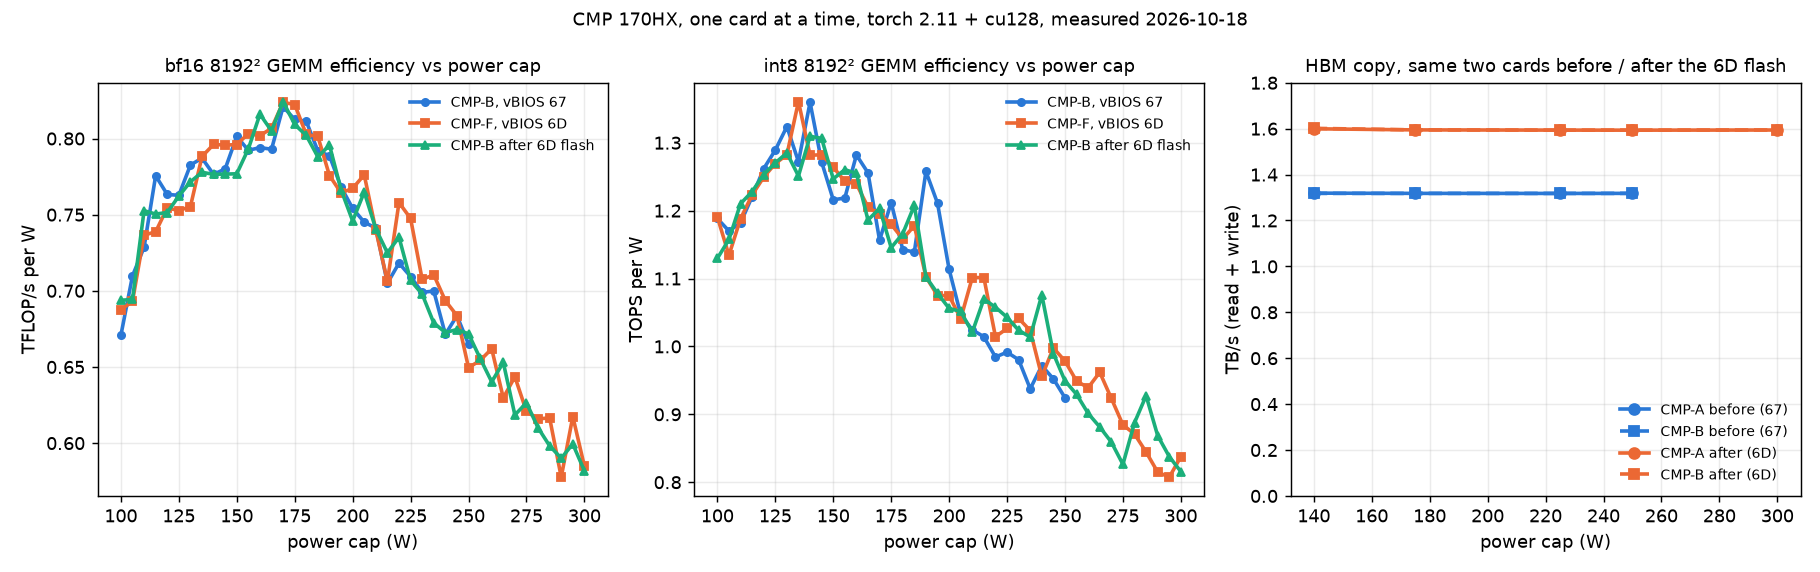

In [10]:
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import Image

COL = ["#2a78d6", "#eb6834", "#1baf7a"]   # categorical slots 1-3, fixed order
MARK = ["o", "s", "^"]
os.makedirs(CHART_DIR, exist_ok=True)

fig, axes = plt.subplots(1, 3, figsize=(14, 4.4))
for ax, dt, unit in ((axes[0], "bf16", "TFLOP/s per W"), (axes[1], "int8", "TOPS per W")):
    for (k, v), c, m in zip(sweep.items(), COL, MARK):
        pts = sorted((r["cap"], r["perW"]) for r in v if r["dtype"] == dt)
        ax.plot([p[0] for p in pts], [p[1] for p in pts], color=c, marker=m, markersize=4, linewidth=2, label=k)
    ax.set_title(f"{dt} 8192² GEMM efficiency vs power cap", fontsize=10)
    ax.set_xlabel("power cap (W)"); ax.set_ylabel(unit); ax.grid(alpha=.25); ax.legend(fontsize=8, frameon=False)

ax = axes[2]
series = [("CMP-A before (67)", "pre6d", "cmp-a"), ("CMP-B before (67)", "pre6d", "cmp-b"),
          ("CMP-A after (6D)", "post6d", "cmp-a"), ("CMP-B after (6D)", "post6d", "cmp-b")]
for lab, phase, card in series:
    pts = sorted((cap, r["median"]) for (ph, cd, cap), rs in prepost.items() if ph == phase and cd == card for r in rs if r["shape"] == "copy")
    c = COL[0] if phase == "pre6d" else COL[1]
    ax.plot([p[0] for p in pts], [p[1] for p in pts], color=c, marker="o" if card == "cmp-a" else "s", markersize=6,
            linewidth=2, linestyle="-" if card == "cmp-a" else "--", label=lab)
ax.set_ylim(0, 1.8); ax.set_title("HBM copy, same two cards before / after the 6D flash", fontsize=10)
ax.set_xlabel("power cap (W)"); ax.set_ylabel("TB/s (read + write)"); ax.grid(alpha=.25); ax.legend(fontsize=8, frameon=False, loc="lower right")
fig.suptitle("CMP 170HX, one card at a time, torch 2.11 + cu128, measured 2026-10-18", fontsize=10)
fig.tight_layout()
chart = os.path.join(CHART_DIR, EXPERIMENT)
fig.savefig(chart + ".png", dpi=130); fig.savefig(chart + ".svg")
with open(chart + ".svg") as f:   # drop matplotlib's trailing spaces so `git diff --check` stays clean
    svg = "\n".join(line.rstrip() for line in f.read().splitlines()) + "\n"
with open(chart + ".svg", "w") as f:
    f.write(svg)
plt.close(fig)
display(Image(chart + ".png"))

## 3. Reproduce

**Hardware.** One memory-unlocked CMP 170HX per run (any number of cards, measured one at a time), directed airflow,
live temperature monitoring. run10, run11, run13 and run_fleet kill the run at 83 °C core / 90 °C HBM (the 5 W sweep
adds an external watchdog at 85 / 92 °C) and restore the cap; run9 has no kill switch, so watch it yourself. Stop at
once on an Xid.

```bash
python -m venv venv && . venv/bin/activate
pip install torch==2.11.0 --index-url https://download.pytorch.org/whl/cu128
cd results/2026-10-18-cmp170hx-gemm-dtype-power-6d/tools

# 2.1 full dtype table, one card, 225 W then 140 W
IDX=<nvidia-smi index> GPU_UUID=<GPU-uuid> PY=python OUT=. bash run9.sh
python an9.py .            # Markdown table like receipts/dtype_table_67/TABLE_*.md
# 2.2 subset table, 140 W then 300 W (6D card)
IDX=<idx> GPU_UUID=<GPU-uuid> PY=python OUT=. bash run10.sh
# 2.3 5 W cap sweep under continuous load, 100 W .. HI W
CARDS="<idx>:<GPU-uuid>:cmp-x:300" RESTORE=140 PY=python OUT=. bash run13.sh
# 2.4 cap sweep before / after a flash
CARDS="<idx>:<GPU-uuid>:cmp-x" CAPS="140 175 225 250 300" PY=python OUT=. bash run11.sh
# 2.5 fleet check at 170 W (set the cap first: sudo nvidia-smi -i <idx> -pl 170)
CARDS="<idx>:cmp-a <idx>:cmp-b" PY=python OUT=. bash run_fleet.sh
```

`an9.py` / `an10.py` expect the file names used under `receipts/` (`res9_cmp-c_<cap>.jsonl` …); rename or edit the
pattern for your own run. Cap changes need `sudo -n nvidia-smi -pl` rights.

Flashing 67 → 6D is irreversible without a saved ROM and can brick a card; the steps that worked for us, and the
traps, are in the [result README](../results/2026-10-18-cmp170hx-gemm-dtype-power-6d/README.md#flashing-67--6d-what-worked).

## 4. Appendix

<details>
<summary>Method details, caveats, what was not measured</summary>

- Timing: CUDA events around `iters` back-to-back calls sized to ~2 s (mm9, mm10) or ~1 s (mm11) after 3 warm-up calls;
  each cell is the median of 3 (mm9, mm10) or 2 (mm11) such runs. Short bursts ran hotter clocks and overstated low caps in
  earlier attempts, so all cells here are sustained.
- int8 uses `torch._int_mm` (int32 output). B column-major (`(n, k)` tensor transposed) takes the fast IMMA path; a plain
  row-major B silently takes a ~4x slower path.
- HBM copy = `y.copy_(x)` of 2 GiB (mm9, mm10) or 1 GiB (mm11), read + write bytes counted.
- '% of peak' is relative to the A100's dense per-SM rate scaled to 70 SMs and the measured mean SM clock; it says how well
  the clock is used, not how far the card is from an A100.
- Power per point in the 5 W sweep comes from 1–4 sampler readings; single points are noisy (int8 especially). Read the
  shape of the curve, not one point. The 100 ms sampler also shows brief single-sample spikes above the cap
  (up to 415 W in the sweep that ends at 300 W); peaks are listed in 2.6.
- GEMM outputs were not checked against a reference; this is a throughput measurement only.
- Xid / ECC were not scanned during these GEMM runs. Each flashed card passed a 2-pass and a 4-pass memtest (62 GiB,
  0 mismatches, no Xid) before returning to service.
- Not measured: sustained soaks above 250 W (the 6D card in the 5 W sweep reached 82 °C core at the 300 W step under
  continuous load); 74-SM builds (our driver predates cmpunlocker's SM override); P2P builds; non-GEMM kernels
  (attention, MoE routing).
- Host details not needed to reproduce (bus addresses, UUIDs, host names, card indices) are replaced by CMP-A … CMP-G.

</details>

## Try your own query

Edit `QUERY` and run the cell: it prints the matching receipt rows (the "response") and the power / clock / sample
accounting aligned to each row (the "usage"). With `LIVE = True` it first runs `tools/mm11.py` on the visible GPU at
its current cap and queries that fresh output instead.

In [11]:
QUERY = dict(dataset="post6d", card="cmp-b", cap=175, dtype="bf16", M=32)   # dataset: dtype_table_67 | card_6d_140_300 | pre6d | post6d | fleet6d_170w

if LIVE:
    out = subprocess.run([sys.executable, "-I", os.path.join(RESULTS_DIR, "tools", "mm11.py"), "live"], capture_output=True, text=True, check=True).stdout
    rows = [json.loads(l) for l in out.splitlines() if l.strip()]
else:
    pool = {"dtype_table_67": dtype67.get(QUERY.get("cap"), []), "card_6d_140_300": card6d.get(QUERY.get("cap"), []),
            "fleet6d_170w": fleet.get(LABELS.get(QUERY.get("card"), ""), [])}
    rows = pool.get(QUERY["dataset"], prepost.get((QUERY["dataset"], QUERY.get("card"), QUERY.get("cap")), []))
hits = [r for r in rows if r["dtype"] == QUERY["dtype"] and (QUERY.get("M") is None or r.get("M") == QUERY["M"])]
for r in hits:
    print("response:", json.dumps({k: r[k] for k in ("tag", "test", "unit", "median", "lo", "hi", "M", "K", "N") if k in r}))
    if "W" in r:
        print("usage:   ", json.dumps({"mean_W": round(r["W"], 1), "mean_SM_MHz": round(r["MHz"]), "sampler_rows": r["samples"],
                                        "per_W": round(r["perW"], 3), "pct_of_clock_adjusted_peak": None if r["peak_pct"] is None else round(r["peak_pct"], 1)}))
print(len(hits), "matching row(s)")

response: {"tag": "cmp-b_cap175", "test": "bf16", "unit": "TOPS", "median": 33.214254598664596, "lo": 32.745507486474395, "hi": 33.68300171085479, "M": 32, "K": 4096, "N": 4096}
usage:    {"mean_W": 186.3, "mean_SM_MHz": 1083, "sampler_rows": 5, "per_W": 0.178, "pct_of_clock_adjusted_peak": 21.4}
1 matching row(s)
